# Deteksi Tulisan Kaganga (Aksara Ulu Rejang) dengan YOLOv8s

**Project:** Computer Vision - Semester 7  
**Dataset:** Aksara Ulu Rejang (Roboflow)  
**Model:** YOLOv8s (small variant)

---

## Alur Notebook
1. Setup & Install Dependencies
2. Upload & Ekstrak Dataset (Manual ZIP)
3. Validasi & Eksplorasi Dataset
4. Konfigurasi Training YOLOv8s
5. Training Model
6. Evaluasi Lengkap (mAP, Precision, Recall, F1, Confusion Matrix)
7. Visualisasi Training Curves
8. Inference & Demo

>  **Pastikan Runtime → Change Runtime Type → GPU (T4)** sebelum menjalankan!

## CELL 1 — Setup & Install Dependencies

In [ ]:
# ============================================================
# CELL 1: Install semua dependencies yang dibutuhkan
# ============================================================

import subprocess, sys

print(" Menginstall dependencies...")
subprocess.run([sys.executable, "-m", "pip", "install",
                "ultralytics", "roboflow", "supervision",
                "seaborn", "matplotlib", "pandas", "numpy",
                "Pillow", "scikit-learn", "pyyaml",
                "-q"], check=True)

print(" Semua dependencies berhasil diinstall!")

# Cek GPU
import torch
print(f"\n  PyTorch versi : {torch.__version__}")
print(f" CUDA tersedia : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f" GPU           : {torch.cuda.get_device_name(0)}")
    print(f" VRAM          : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("  GPU tidak terdeteksi! Pastikan Runtime sudah di-set ke GPU.")

 Menginstall dependencies...
 Semua dependencies berhasil diinstall!

  PyTorch versi : 2.10.0+cu128
 CUDA tersedia : True
 GPU           : Tesla T4
 VRAM          : 15.6 GB


## CELL 2 — Upload & Ekstrak Dataset

**Langkah download dataset manual:**
1. Buka: https://universe.roboflow.com/novalrizkiansyah-ymail-com/aksara-ulu-rejang
2. Klik **"Download Dataset"**
3. Pilih format: **YOLOv8**
4. Download sebagai **ZIP**
5. Upload ZIP tersebut di cell di bawah

In [ ]:
# ============================================================
# CELL 2: Upload & Ekstrak Dataset ZIP
# ============================================================

import os
import zipfile
import shutil
from google.colab import files
from pathlib import Path

# --- Upload file ZIP dari komputer lokal ---
print(" Silakan upload file ZIP dataset dari Roboflow...")
uploaded = files.upload()

# Ambil nama file ZIP yang diupload
zip_filename = list(uploaded.keys())[0]
print(f"\n File terupload: {zip_filename}")

# Ekstrak ZIP
DATASET_DIR = Path("/content/dataset")
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
DATASET_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall(DATASET_DIR)

print(f" Dataset diekstrak ke: {DATASET_DIR}")
print("\n Struktur direktori:")
for p in sorted(DATASET_DIR.rglob("*"))[:30]:
    print(f"   {p.relative_to(DATASET_DIR)}")

 Silakan upload file ZIP dataset dari Roboflow...


Saving Aksara Ulu Rejang.v2i.yolov8.zip to Aksara Ulu Rejang.v2i.yolov8.zip

 File terupload: Aksara Ulu Rejang.v2i.yolov8.zip
 Dataset diekstrak ke: /content/dataset

 Struktur direktori:
   README.dataset.txt
   README.roboflow.txt
   data.yaml
   test
   test/images
   test/images/103_jpg.rf.9bbd8c9d7defd7ea4de352ced697c4ed.jpg
   test/images/104_jpg.rf.81823e61e224273562ee260f5812c3d9.jpg
   test/images/105_jpg.rf.485c4a03ae5dbeeefb5985ae3f1f3e8d.jpg
   test/images/106_jpg.rf.67146b6a656f23323bb5631b92288bf2.jpg
   test/images/116_jpg.rf.68938e6547701cf7a025b97c72d342e1.jpg
   test/images/119_jpg.rf.4649e9592519d29a45a2515a48cffdd1.jpg
   test/images/129_jpg.rf.bcd5ac81fabd1a6330f6e7693abdeb2a.jpg
   test/images/130_jpg.rf.abad26f41d85ff7238cf08b24ff20ed3.jpg
   test/images/144_jpg.rf.0126114b28ece018613ef7a0daa10f55.jpg
   test/images/160_jpg.rf.1045280d7c5147b3a251e8e1fa373dd6.jpg
   test/images/169_jpg.rf.e704173cdd409ee119f61c9051cb3882.jpg
   test/images/188_jpg.rf.8f6906c9a6c

## CELL 3 — Validasi & Setup data.yaml

 data.yaml ditemukan: /content/dataset/data.yaml

 Isi data.yaml:
   train: ../train/images
   val: ../valid/images
   test: ../test/images
   nc: 253
   names: ['a', 'ah', 'an', 'ang', 'ar', 'aw', 'ay', 'ba', 'bah', 'ban', 'bang', 'bar', 'baw', 'bay', 'be', 'bi', 'bo', 'bu', 'ca', 'cah', 'can', 'cang', 'car', 'caw', 'cay', 'ce', 'ci', 'co', 'cu', 'da', 'dah', 'dan', 'dang', 'dar', 'daw', 'day', 'de', 'di', 'do', 'du', 'e', 'ga', 'gah', 'gan', 'gang', 'gar', 'gaw', 'gay', 'ge', 'gi', 'go', 'gu', 'ha', 'hah', 'han', 'hang', 'har', 'haw', 'hay', 'he', 'hi', 'ho', 'hu', 'i', 'ja', 'jah', 'jan', 'jang', 'jar', 'jaw', 'jay', 'je', 'ji', 'jo', 'ju', 'ka', 'kah', 'kan', 'kang', 'kar', 'kaw', 'kay', 'ke', 'ki', 'ko', 'ku', 'la', 'lah', 'lan', 'lang', 'lar', 'law', 'lay', 'le', 'li', 'lo', 'lu', 'ma', 'mah', 'man', 'mang', 'mar', 'maw', 'may', 'mba', 'mbah', 'mban', 'mbang', 'mbar', 'mbaw', 'mbay', 'mbe', 'mbi', 'mbo', 'mbu', 'me', 'mi', 'mo', 'mu', 'na', 'nah', 'nan', 'nang', 'nar', 'naw', 'na

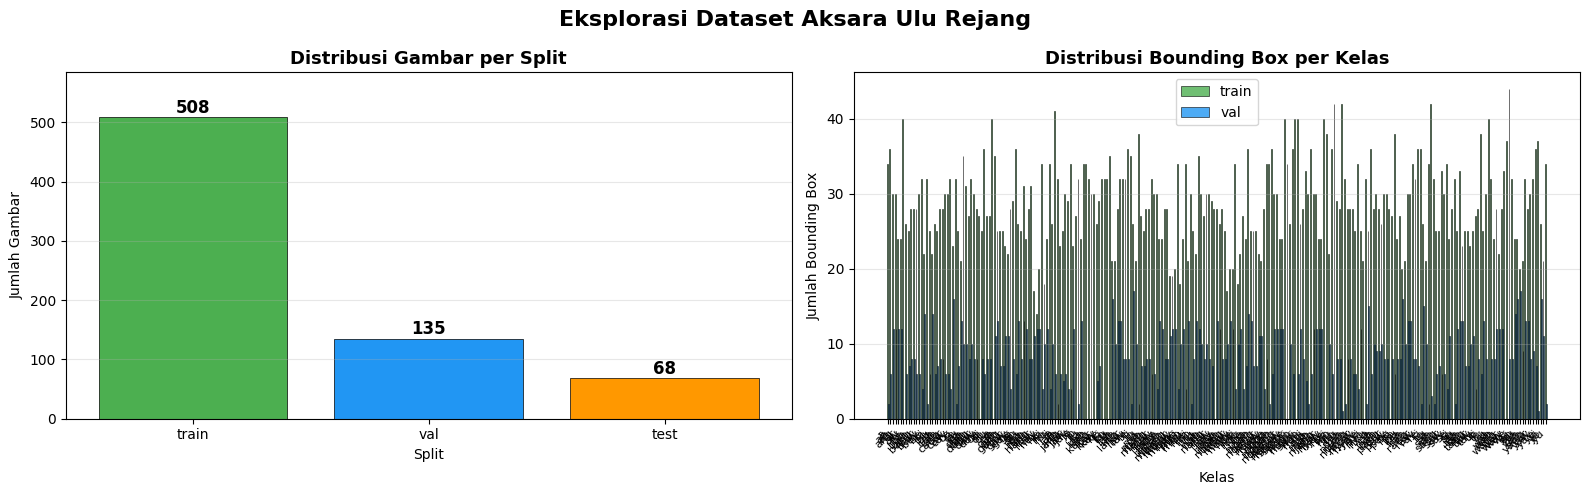

 Eksplorasi dataset selesai!


In [ ]:
import yaml
import glob
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns

DATASET_DIR = Path("/content/dataset")

# --- Temukan data.yaml ---
yaml_files = list(DATASET_DIR.rglob("data.yaml"))
if not yaml_files:
    yaml_files = list(DATASET_DIR.rglob("*.yaml"))

assert yaml_files, " Tidak ditemukan file .yaml! Pastikan format dataset YOLOv8."
DATA_YAML = yaml_files[0]
print(f" data.yaml ditemukan: {DATA_YAML}")

# Baca dan tampilkan isi yaml
with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

print("\n Isi data.yaml:")
for k, v in data_cfg.items():
    print(f"   {k}: {v}")

# --- Fix path di yaml agar absolut ---
# The actual train, valid, test directories are directly under DATASET_DIR.
# The original data.yaml might use relative paths like '../train/images'.
# We need to explicitly set them to the correct absolute paths within DATASET_DIR.
path_mapping = {
    'train': 'train',
    'val': 'valid', # Map 'val' key to 'valid' directory
    'test': 'test'
}
for split_key, dir_name in path_mapping.items():
    if split_key in data_cfg:
        data_cfg[split_key] = str(DATASET_DIR / dir_name / 'images')

with open(DATA_YAML, 'w') as f:
    yaml.dump(data_cfg, f)
print("\n Path di data.yaml sudah di-fix ke absolut path.")

# --- Hitung jumlah data per split ---
class_names = data_cfg.get('names', [])
nc = data_cfg.get('nc', len(class_names))

print(f"\n Info Dataset:")
print(f"   Jumlah kelas : {nc}")
print(f"   Nama kelas   : {class_names}")

split_counts = {}
for split in ['train', 'val', 'test']:
    if split in data_cfg:
        img_dir = Path(data_cfg[split])
        imgs = list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png")) + list(img_dir.glob("*.jpeg"))
        split_counts[split] = len(imgs)
        print(f"   {split:8s}: {len(imgs)} gambar")

# --- Hitung distribusi label per kelas ---
class_counts = {split: np.zeros(nc, dtype=int) for split in split_counts}
for split in split_counts:
    img_dir = Path(data_cfg[split])
    label_dir = img_dir.parent / 'labels' if 'labels' not in str(img_dir) else img_dir.parent.parent / 'labels' / split
    # Coba beberapa lokasi label
    possible_label_dirs = [
        img_dir.parent / 'labels',
        img_dir.parent.parent / 'labels' / split,
        Path(str(img_dir).replace('images', 'labels')),
    ]
    label_dir = None
    for d in possible_label_dirs:
        if d.exists():
            label_dir = d
            break
    if label_dir:
        for lf in label_dir.glob("*.txt"):
            with open(lf) as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        cls_id = int(parts[0])
                        if cls_id < nc:
                            class_counts[split][cls_id] += 1

# --- Visualisasi Distribusi Dataset ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Eksplorasi Dataset Aksara Ulu Rejang',
             fontsize=16, fontweight='bold')

# Plot 1: Jumlah gambar per split
ax = axes[0]
colors = ['#4CAF50', '#2196F3', '#FF9800']
bars = ax.bar(split_counts.keys(), split_counts.values(), color=colors[:len(split_counts)], edgecolor='black', linewidth=0.5)
for bar, val in zip(bars, split_counts.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, str(val),
            ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.set_title('Distribusi Gambar per Split', fontsize=13, fontweight='bold')
ax.set_xlabel('Split')
ax.set_ylabel('Jumlah Gambar')
ax.set_ylim(0, max(split_counts.values()) * 1.15)
ax.grid(axis='y', alpha=0.3)

# Plot 2: Distribusi label per kelas (train)
ax2 = axes[1]
if 'train' in class_counts and class_counts['train'].sum() > 0:
    x = np.arange(nc)
    width = 0.35
    splits_with_labels = [s for s in ['train', 'val'] if s in class_counts and class_counts[s].sum() > 0]
    palette = ['#4CAF50', '#2196F3']
    for i, (sp, col) in enumerate(zip(splits_with_labels, palette)):
        offset = (i - len(splits_with_labels)/2 + 0.5) * width
        ax2.bar(x + offset, class_counts[sp], width, label=sp, color=col, alpha=0.8, edgecolor='black', linewidth=0.5)
    ax2.set_title('Distribusi Bounding Box per Kelas', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Kelas')
    ax2.set_ylabel('Jumlah Bounding Box')
    short_names = [n[:10] for n in class_names] if class_names else [str(i) for i in range(nc)]
    ax2.set_xticks(x)
    ax2.set_xticklabels(short_names, rotation=45, ha='right', fontsize=8)
    ax2.legend()
    ax2.grid(axis='y', alpha=0.3)
else:
    ax2.text(0.5, 0.5, 'Label stats tidak tersedia\n(lokasi labels/ berbeda)',
             ha='center', va='center', transform=ax2.transAxes, fontsize=12)

plt.tight_layout()
plt.savefig('/content/dataset_exploration.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Eksplorasi dataset selesai!")

## CELL 4 — Preview Sampel Gambar Dataset

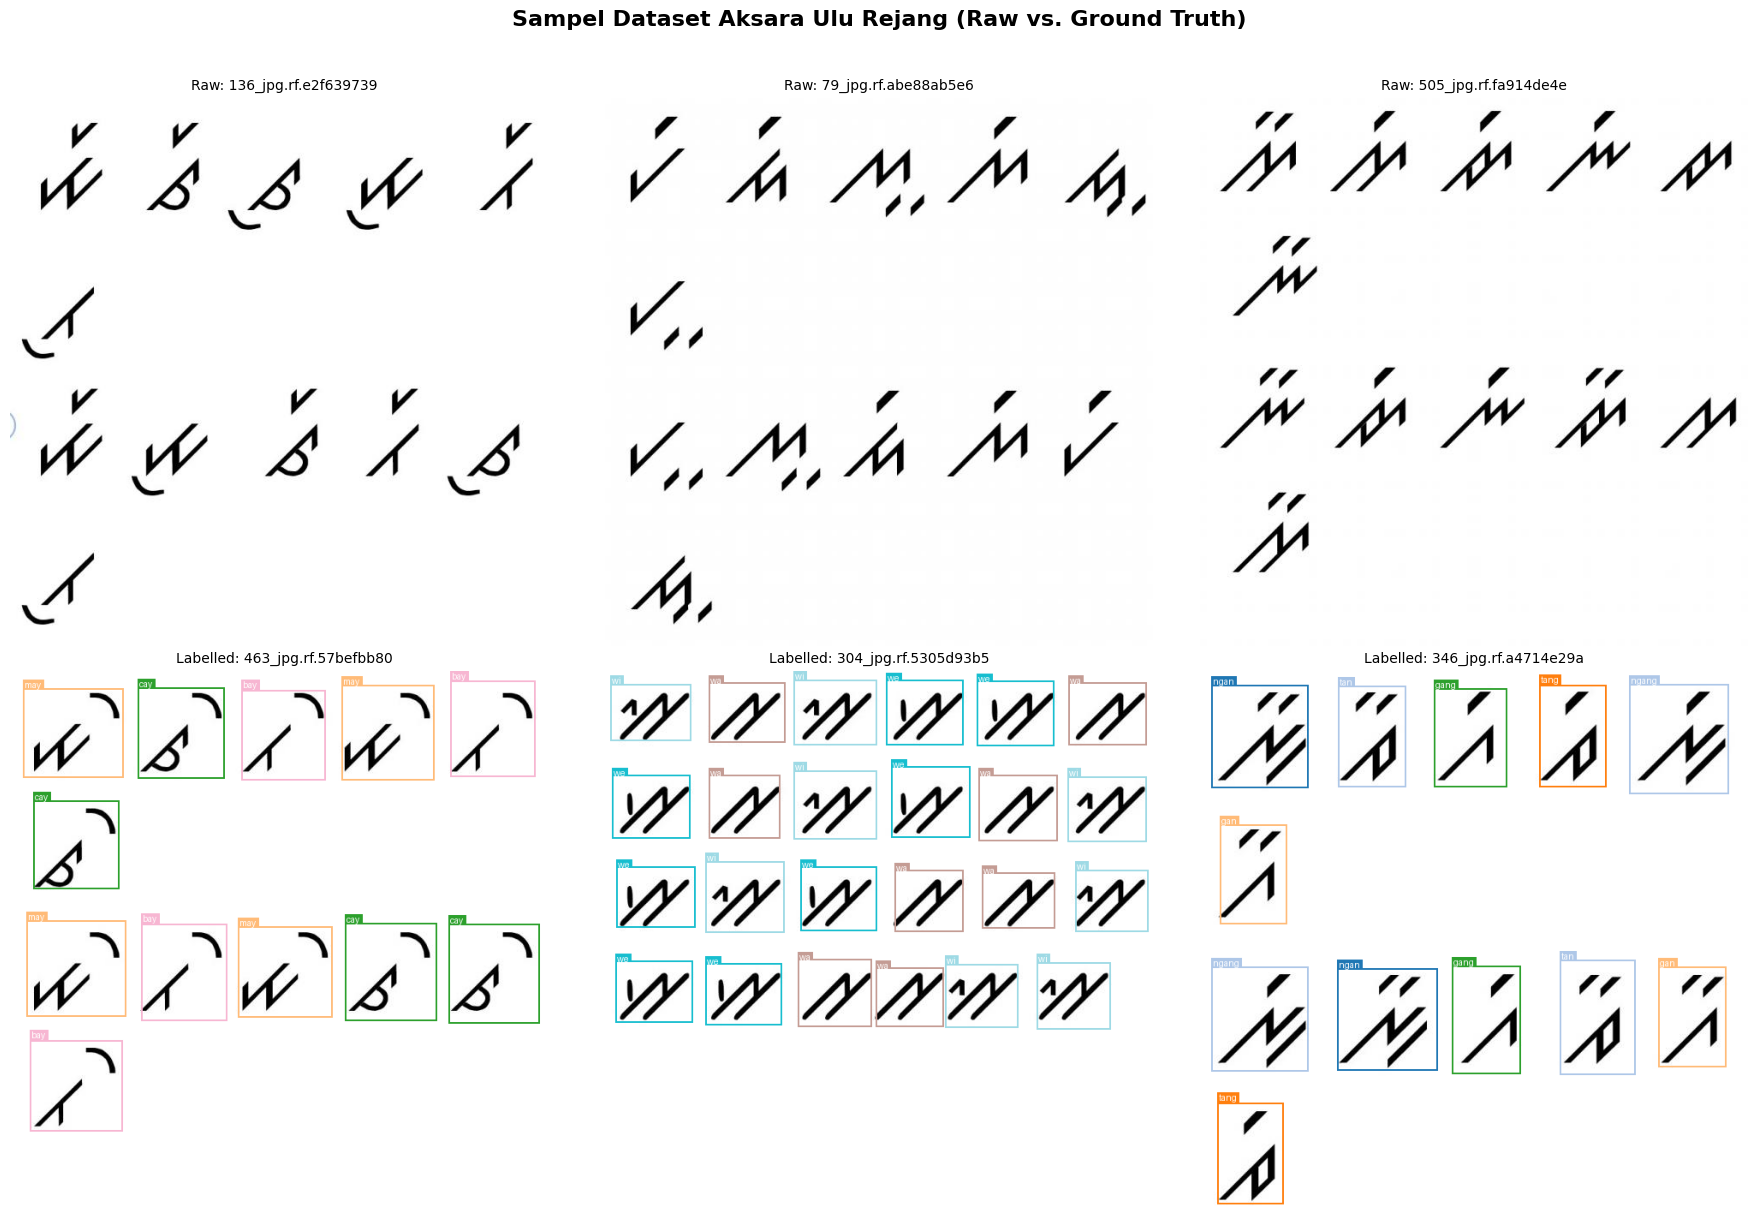

Preview sampel dataset selesai!


In [ ]:
# ============================================================
# CELL 4: Tampilkan sampel gambar dengan dan tanpa bounding box
# ============================================================

import random
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from pathlib import Path
import yaml

DATASET_DIR = Path("/content/dataset")
DATA_YAML = list(DATASET_DIR.rglob("data.yaml"))[0]
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)

class_names = cfg.get('names', [])

# Dapatkan path direktori gambar untuk setiap split
train_img_dir = Path(cfg.get('train', ''))
val_img_dir   = Path(cfg.get('val', ''))
test_img_dir  = Path(cfg.get('test', ''))

# Kumpulkan semua gambar dari masing-masing split
all_train_imgs = list(train_img_dir.glob("*.jpg")) + list(train_img_dir.glob("*.png"))
all_val_imgs   = list(val_img_dir.glob("*.jpg")) + list(val_img_dir.glob("*.png"))
all_test_imgs  = list(test_img_dir.glob("*.jpg")) + list(test_img_dir.glob("*.png"))

# Warna per kelas untuk bounding box
COLORS = plt.cm.tab20.colors

def draw_yolo_boxes(img_path, class_names):
    img = Image.open(img_path).convert('RGB')
    W, H = img.size
    draw = ImageDraw.Draw(img)

    # Load a default font
    try:
        font = ImageFont.truetype("arial.ttf", 12) # Try to load Arial if available
    except IOError:
        font = ImageFont.load_default() # Fallback to default PIL font

    # Cari label file
    label_path = Path(str(img_path).replace('images', 'labels').replace('.jpg', '.txt').replace('.png', '.txt'))
    if not label_path.exists():
        return img # Return original image if no label file

    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(parts[0])
            cx, cy, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
            x1 = int((cx - bw/2) * W)
            y1 = int((cy - bh/2) * H)
            x2 = int((cx + bw/2) * W)
            y2 = int((cy + bh/2) * H)
            color = tuple(int(c*255) for c in COLORS[cls_id % len(COLORS)][:3])
            draw.rectangle([x1, y1, x2, y2], outline=color, width=2)
            label = class_names[cls_id] if cls_id < len(class_names) else str(cls_id)
            # Make sure text doesn't go out of bounds
            # Use textbbox to get text dimensions
            bbox = draw.textbbox((0, 0), label, font=font)
            text_w, text_h = bbox[2] - bbox[0], bbox[3] - bbox[1]

            text_y1 = max(0, y1 - text_h - 2)
            draw.rectangle([x1, text_y1, x1 + text_w + 4, y1], fill=color)
            draw.text((x1+2, text_y1), label, fill='white', font=font)
    return img

def show_raw_image(img_path):
    """Loads and returns an image without drawing any boxes."""
    return Image.open(img_path).convert('RGB')

# Pilih sampel gambar: 1 dari setiap split (train, val, test) untuk setiap kategori (raw dan labelled)
# Pastikan ada cukup gambar di setiap split
raw_sample_imgs = []
labelled_sample_imgs = []

if all_train_imgs:
    raw_sample_imgs.append(random.choice(all_train_imgs))
    labelled_sample_imgs.append(random.choice(all_train_imgs))
if all_val_imgs:
    raw_sample_imgs.append(random.choice(all_val_imgs))
    labelled_sample_imgs.append(random.choice(all_val_imgs))
if all_test_imgs:
    raw_sample_imgs.append(random.choice(all_test_imgs))
    labelled_sample_imgs.append(random.choice(all_test_imgs))


# Plot grid 2x3: Baris 1 untuk gambar tanpa label, Baris 2 untuk gambar dengan label
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Sampel Dataset Aksara Ulu Rejang (Raw vs. Ground Truth)',
             fontsize=16, fontweight='bold', y=1.02)

# Gambar tanpa label
for i, img_path in enumerate(raw_sample_imgs):
    ax = axes[0, i]
    img = show_raw_image(img_path)
    ax.imshow(img)
    ax.set_title(f"Raw: {img_path.name[:20]}", fontsize=10)
    ax.axis('off')

# Gambar dengan label (Ground Truth)
for i, img_path in enumerate(labelled_sample_imgs):
    ax = axes[1, i]
    img = draw_yolo_boxes(img_path, class_names)
    ax.imshow(img)
    ax.set_title(f"Labelled: {img_path.name[:20]}", fontsize=10)
    ax.axis('off')

# Sembunyikan subplot yang tidak digunakan jika ada kurang dari 3 sampel per kategori
for i in range(len(raw_sample_imgs), 3):
    axes[0, i].axis('off')
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig('/content/dataset_samples.png', dpi=120, bbox_inches='tight')
plt.show()
print("Preview sampel dataset selesai!")


## CELL 5 — Konfigurasi Hyperparameter Training

In [ ]:
# ============================================================
# CELL 5: Konfigurasi hyperparameter training YOLOv8s
# ============================================================

from pathlib import Path
import yaml

DATASET_DIR = Path("/content/dataset")
DATA_YAML   = str(list(DATASET_DIR.rglob("data.yaml"))[0])

# =============================================
#  HYPERPARAMETER — BISA DIUBAH SESUAI KEBUTUHAN
# =============================================
TRAIN_CFG = {
    # Model
    "model"       : "yolov8s.pt",   # YOLOv8 Small (pretrained COCO)
    "data"        : DATA_YAML,

    # Training
    "epochs"      : 100,            # Jumlah epoch (naikan ke 150 jika dataset besar)
    "imgsz"       : 640,            # Ukuran gambar input
    "batch"       : 16,             # Batch size (kurangi ke 8 jika OOM)
    "patience"    : 20,             # Early stopping patience

    # Optimizer
    "optimizer"   : "AdamW",        # Optimizer (SGD / AdamW / Adam)
    "lr0"         : 1e-3,           # Learning rate awal
    "lrf"         : 0.01,           # LR akhir (lr0 * lrf)
    "momentum"    : 0.937,
    "weight_decay": 5e-4,
    "warmup_epochs": 3.0,

    # Augmentasi
    "hsv_h"       : 0.015,          # Hue augmentasi
    "hsv_s"       : 0.7,            # Saturation augmentasi
    "hsv_v"       : 0.4,            # Value augmentasi
    "degrees"     : 10.0,           # Rotasi (penting untuk aksara)
    "translate"   : 0.1,
    "scale"       : 0.5,
    "shear"       : 2.0,
    "flipud"      : 0.0,            # No flip vertikal (aksara sensitif orientasi)
    "fliplr"      : 0.0,            # No flip horizontal (aksara sensitif orientasi)
    "mosaic"      : 1.0,            # Mosaic augmentation
    "mixup"       : 0.1,
    "copy_paste"  : 0.1,

    # Output
    "project"     : "/content/runs",
    "name"        : "kaganga_yolov8s",
    "save_period" : 10,             # Simpan checkpoint setiap N epoch
    "plots"       : True,           # Simpan plots otomatis
    "verbose"     : True,
    "device"      : 0,              # 0 = GPU pertama
    "workers"     : 2,              # DataLoader workers
    "seed"        : 42,             # Reproducibility
    "rect"        : False,
    "cos_lr"      : True,           # Cosine LR scheduler
    "label_smoothing": 0.05,
    "nbs"         : 64,             # Nominal batch size
}

print(" Konfigurasi Training:")
print("="*50)
for k, v in TRAIN_CFG.items():
    print(f"  {k:<20}: {v}")
print("="*50)
print("\n Konfigurasi siap. Lanjut ke training!")

 Konfigurasi Training:
  model               : yolov8s.pt
  data                : /content/dataset/data.yaml
  epochs              : 100
  imgsz               : 640
  batch               : 16
  patience            : 20
  optimizer           : AdamW
  lr0                 : 0.001
  lrf                 : 0.01
  momentum            : 0.937
  weight_decay        : 0.0005
  warmup_epochs       : 3.0
  hsv_h               : 0.015
  hsv_s               : 0.7
  hsv_v               : 0.4
  degrees             : 10.0
  translate           : 0.1
  scale               : 0.5
  shear               : 2.0
  flipud              : 0.0
  fliplr              : 0.0
  mosaic              : 1.0
  mixup               : 0.1
  copy_paste          : 0.1
  project             : /content/runs
  name                : kaganga_yolov8s
  save_period         : 10
  plots               : True
  verbose             : True
  device              : 0
  workers             : 2
  seed                : 42
  rect                

## CELL 6 — Training YOLOv8s

In [ ]:
# ============================================================
# CELL 6: Training YOLOv8s
# ============================================================

from ultralytics import YOLO
import torch
import time

print("Memulai Training YOLOv8s...")
print(f"Waktu mulai: {time.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Device: {'GPU - ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print("="*60)

# Load model pretrained YOLOv8s (download otomatis ~22MB)
model = YOLO(TRAIN_CFG.pop("model"))

start_time = time.time()

# Training
results = model.train(**TRAIN_CFG)

elapsed = time.time() - start_time
print("\n" + "="*60)
print(f"Training selesai!")
print(f"Total waktu  : {elapsed/60:.1f} menit")
print(f"Hasil disimpan di: /content/runs/kaganga_yolov8s/")

# Simpan path model terbaik
import glob
best_model_paths = glob.glob("/content/runs/kaganga_yolov8s/weights/best.pt")
BEST_MODEL = best_model_paths[0] if best_model_paths else None
print(f"Best model     : {BEST_MODEL}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Memulai Training YOLOv8s...
Waktu mulai: 2026-05-03 08:33:25
Device: GPU - Tesla T4
WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epo

## CELL 7 — Evaluasi Lengkap: mAP, Precision, Recall, F1

In [ ]:
# ============================================================
# CELL 7: Evaluasi model pada validation/test set
# ============================================================

from ultralytics import YOLO
import yaml, glob
from pathlib import Path
import pandas as pd
import numpy as np

# Load best model
BEST_MODEL = glob.glob("/content/runs/kaganga_yolov8s/weights/best.pt")[0]
model = YOLO(BEST_MODEL)
DATA_YAML = str(list(Path("/content/dataset").rglob("data.yaml"))[0])

print(" Menjalankan evaluasi pada Validation Set...")
print("="*60)

# Evaluasi pada val set
val_metrics = model.val(
    data=DATA_YAML,
    split='val',
    imgsz=640,
    batch=16,
    conf=0.001,   # Threshold rendah untuk menghitung semua prediksi
    iou=0.6,
    device=0,
    plots=True,
    save_json=True,
    project="/content/runs",
    name="kaganga_eval",
    verbose=True,
)

# Ambil class names
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
class_names = cfg.get('names', [])

# ---- Tampilkan metrik global ----
print("\n" + "="*60)
print(" HASIL EVALUASI GLOBAL")
print("="*60)
print(f"  mAP@50         : {val_metrics.box.map50:.4f}  ({val_metrics.box.map50*100:.2f}%)")
print(f"  mAP@50-95      : {val_metrics.box.map:.4f}  ({val_metrics.box.map*100:.2f}%)")
print(f"  Precision (P)  : {val_metrics.box.mp:.4f}  ({val_metrics.box.mp*100:.2f}%)")
print(f"  Recall    (R)  : {val_metrics.box.mr:.4f}  ({val_metrics.box.mr*100:.2f}%)")

# F1 score
P = val_metrics.box.mp
R = val_metrics.box.mr
F1 = 2 * P * R / (P + R + 1e-10)
print(f"  F1 Score       : {F1:.4f}  ({F1*100:.2f}%)")
print("="*60)

# ---- Per-class metrics ----
print("\n METRIK PER KELAS:")
print("="*60)

# Ambil data per kelas dari results
ap50_per_class = val_metrics.box.ap50
p_per_class    = val_metrics.box.p
r_per_class    = val_metrics.box.r

rows = []
for i, cls_name in enumerate(class_names):
    if i < len(ap50_per_class):
        p_cls  = float(p_per_class[i])  if i < len(p_per_class)  else 0.0
        r_cls  = float(r_per_class[i])  if i < len(r_per_class)  else 0.0
        f1_cls = 2 * p_cls * r_cls / (p_cls + r_cls + 1e-10)
        ap_cls = float(ap50_per_class[i])
        rows.append({
            'Kelas'       : cls_name,
            'Precision'   : round(p_cls,  4),
            'Recall'      : round(r_cls,  4),
            'F1-Score'    : round(f1_cls, 4),
            'AP@50'       : round(ap_cls, 4),
        })

df_metrics = pd.DataFrame(rows)
if not df_metrics.empty:
    # Tambahkan baris rata-rata
    mean_row = df_metrics[['Precision','Recall','F1-Score','AP@50']].mean()
    mean_row['Kelas'] = ' RATA-RATA'
    df_metrics = pd.concat([df_metrics, pd.DataFrame([mean_row])], ignore_index=True)

    pd.set_option('display.max_rows', 100)
    pd.set_option('display.float_format', '{:.4f}'.format)
    print(df_metrics.to_string(index=False))
    df_metrics.to_csv('/content/per_class_metrics.csv', index=False)
    print("\n Tabel metrik disimpan ke /content/per_class_metrics.csv")
else:
    print(" Data per-kelas tidak tersedia.")

 Menjalankan evaluasi pada Validation Set...
Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,223,495 parameters, 0 gradients, 29.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1075.9±384.6 MB/s, size: 22.6 KB)
val: Scanning /content/dataset/valid/labels.cache... 135 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 135/135 62.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.1it/s 4.2s
                   all        135       1941       0.92      0.984      0.991       0.79
                     a          1          2       0.84          1      0.995      0.796
                    ah          1          6      0.921          1      0.995       0.77
                    an          2         12          1      0.595      0.995      0.801
                   ang          2         12      0.973          1      0.995      0.787
    

## CELL 8 — Visualisasi Training Curves

 Kolom tersedia: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


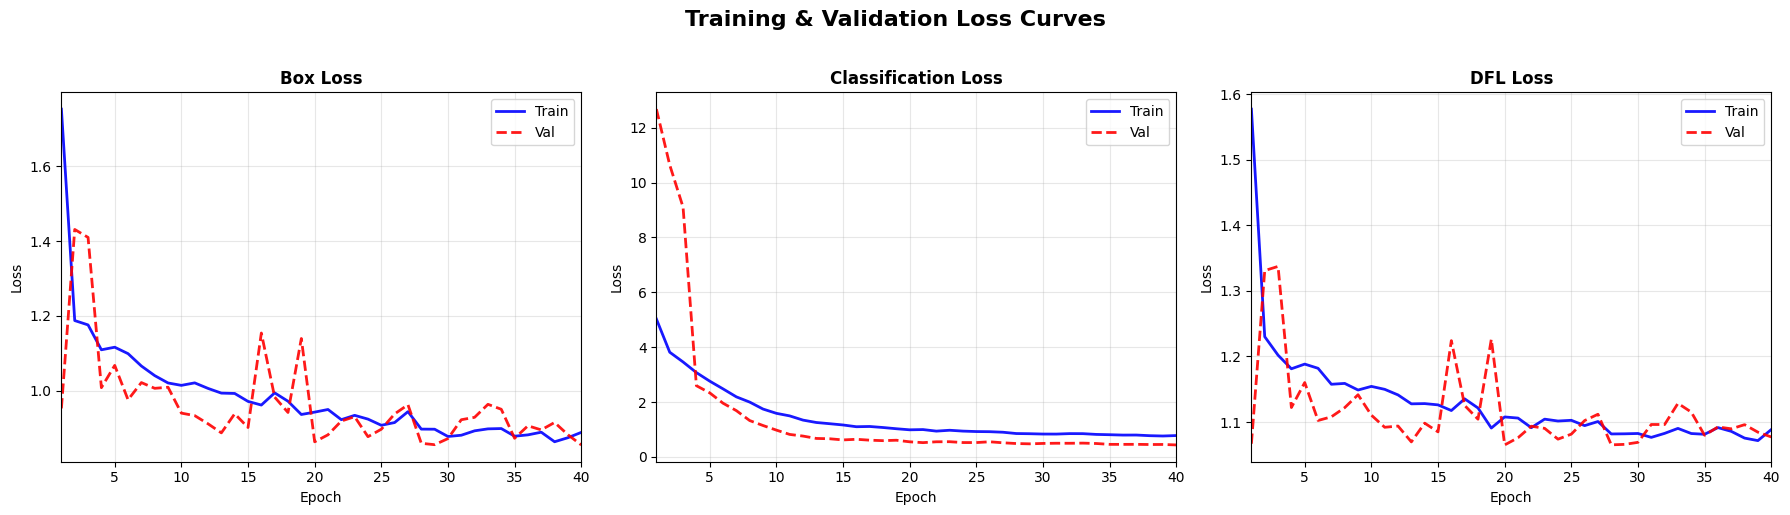

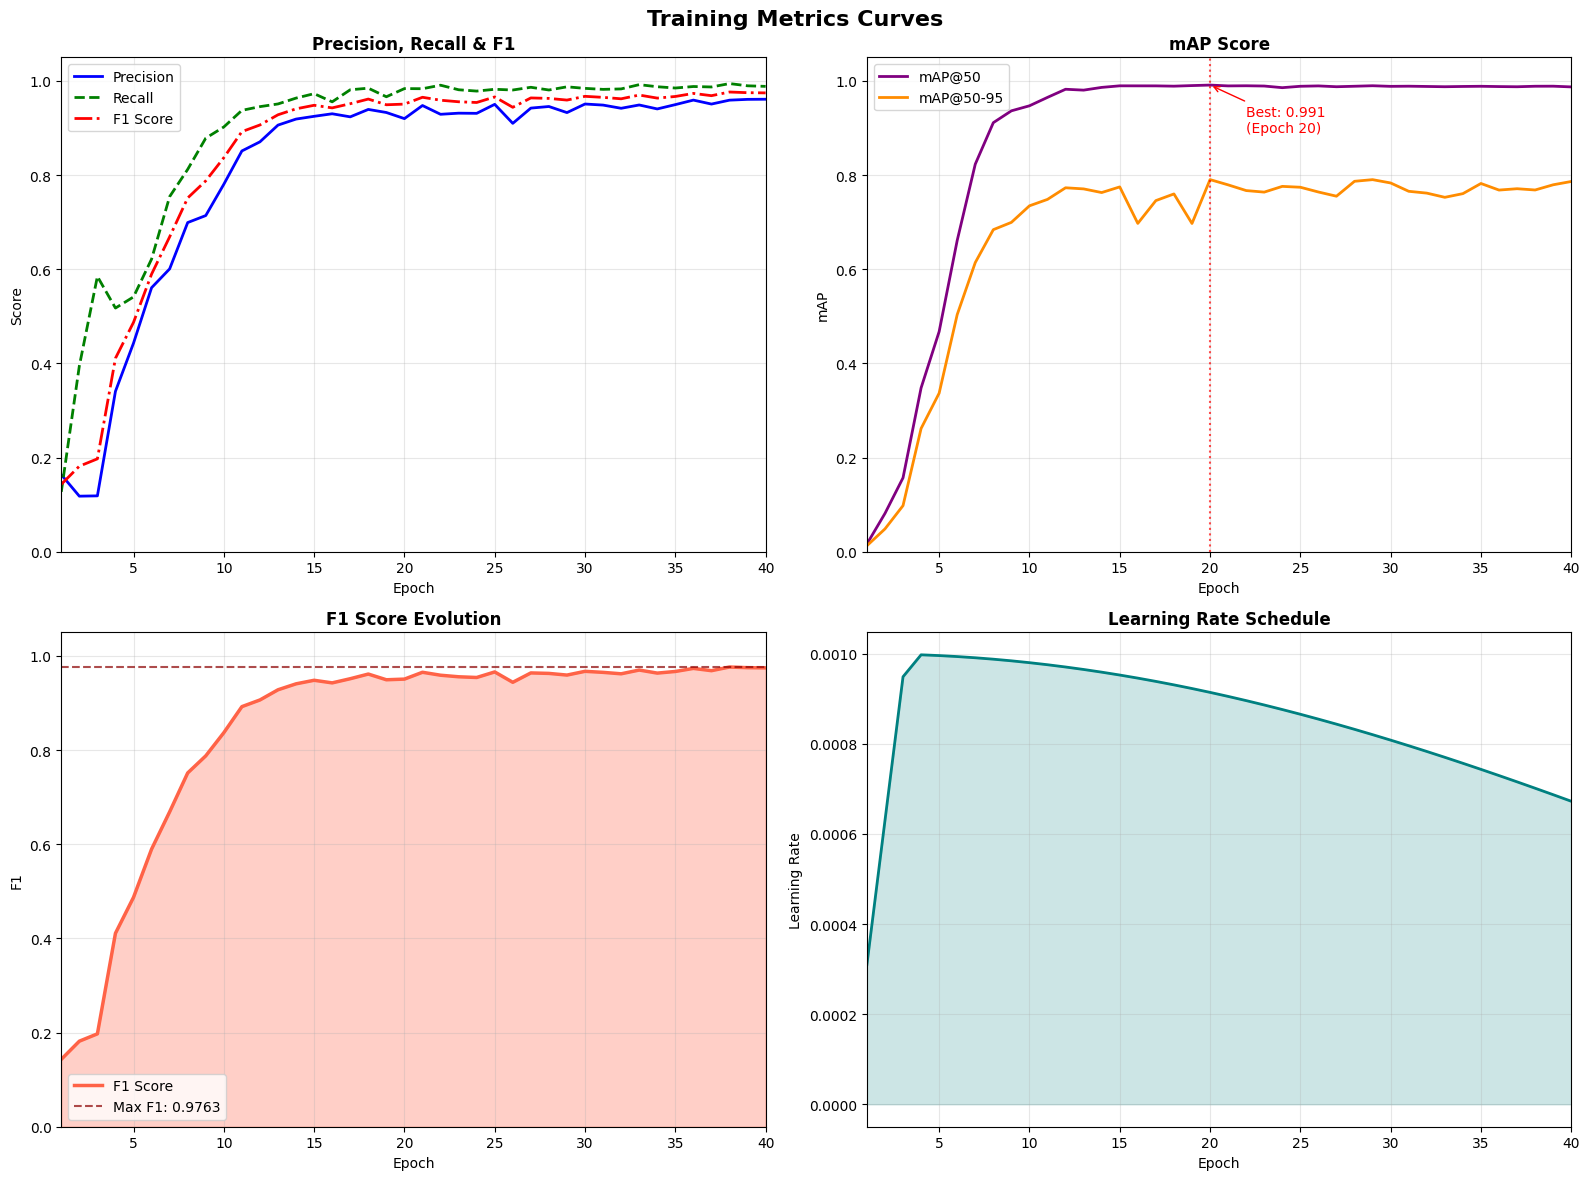


 SUMMARY TRAINING (Epoch Terbaik)
  Best Epoch     : 20
  Precision      : 0.9198
  Recall         : 0.9836
  F1 Score       : 0.9507
  mAP@50         : 0.9911
  mAP@50-95      : 0.7903

 Training curves berhasil diplot & disimpan!


In [ ]:
# ============================================================
# CELL 8: Plot training curves dari results.csv
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import glob
from pathlib import Path
import numpy as np

# Temukan results.csv
csv_files = glob.glob("/content/runs/kaganga_yolov8s/results.csv")
assert csv_files, " results.csv tidak ditemukan! Pastikan training sudah selesai."

df = pd.read_csv(csv_files[0])
df.columns = df.columns.str.strip()  # Bersihkan spasi
print(" Kolom tersedia:", df.columns.tolist())

# Mapping kolom YOLOv8 results.csv
col_map = {
    'box_loss_train' : 'train/box_loss',
    'cls_loss_train' : 'train/cls_loss',
    'dfl_loss_train' : 'train/dfl_loss',
    'box_loss_val'   : 'val/box_loss',
    'cls_loss_val'   : 'val/cls_loss',
    'dfl_loss_val'   : 'val/dfl_loss',
    'precision'      : 'metrics/precision(B)',
    'recall'         : 'metrics/recall(B)',
    'mAP50'         : 'metrics/mAP50(B)',
    'mAP5095'       : 'metrics/mAP50-95(B)',
    'lr'             : 'lr/pg0',
}

def get_col(key):
    col = col_map.get(key, key)
    return df[col] if col in df.columns else None

epochs = range(1, len(df) + 1)

# ================================================
# FIGURE 1: Loss Curves
# ================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Training & Validation Loss Curves', fontsize=16, fontweight='bold', y=1.02)

loss_pairs = [
    ('box_loss_train', 'box_loss_val', 'Box Loss'),
    ('cls_loss_train', 'cls_loss_val', 'Classification Loss'),
    ('dfl_loss_train', 'dfl_loss_val', 'DFL Loss'),
]
for ax, (train_k, val_k, title) in zip(axes, loss_pairs):
    t = get_col(train_k)
    v = get_col(val_k)
    if t is not None:
        ax.plot(epochs, t, 'b-', linewidth=2, label='Train', alpha=0.9)
    if v is not None:
        ax.plot(epochs, v, 'r--', linewidth=2, label='Val', alpha=0.9)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xlim(1, len(df))

plt.tight_layout()
plt.savefig('/content/loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ================================================
# FIGURE 2: Metrics Curves (P, R, mAP, F1)
# ================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Training Metrics Curves', fontsize=16, fontweight='bold')

P_series   = get_col('precision')
R_series   = get_col('recall')
mAP50      = get_col('mAP50')
mAP5095    = get_col('mAP5095')
lr_series  = get_col('lr')

# Precision & Recall
ax = axes[0,0]
if P_series is not None: ax.plot(epochs, P_series, 'b-', lw=2, label='Precision')
if R_series is not None: ax.plot(epochs, R_series, 'g--', lw=2, label='Recall')
if P_series is not None and R_series is not None:
    F1_series = 2 * P_series * R_series / (P_series + R_series + 1e-10)
    ax.plot(epochs, F1_series, 'r-.', lw=2, label='F1 Score')
ax.set_title('Precision, Recall & F1', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Score')
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3)
ax.set_xlim(1, len(df))

# mAP
ax = axes[0,1]
if mAP50   is not None: ax.plot(epochs, mAP50,   'purple',   lw=2, label='mAP@50')
if mAP5095 is not None: ax.plot(epochs, mAP5095, 'darkorange', lw=2, label='mAP@50-95')
ax.set_title('mAP Score', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('mAP')
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3)
ax.set_xlim(1, len(df))
# Tandai epoch terbaik
if mAP50 is not None:
    best_epoch = mAP50.idxmax() + 1
    best_val = mAP50.max()
    ax.axvline(best_epoch, color='red', linestyle=':', alpha=0.7)
    ax.annotate(f'Best: {best_val:.3f}\n(Epoch {best_epoch})',
                xy=(best_epoch, best_val), xytext=(best_epoch+2, best_val-0.1),
                arrowprops=dict(arrowstyle='->', color='red'), fontsize=10, color='red')

# F1 detail
ax = axes[1,0]
if P_series is not None and R_series is not None:
    F1_series = 2 * P_series * R_series / (P_series + R_series + 1e-10)
    ax.fill_between(epochs, F1_series, alpha=0.3, color='tomato')
    ax.plot(epochs, F1_series, 'tomato', lw=2.5, label='F1 Score')
    ax.axhline(F1_series.max(), color='darkred', linestyle='--', alpha=0.7,
               label=f'Max F1: {F1_series.max():.4f}')
ax.set_title('F1 Score Evolution', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('F1')
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3)
ax.set_xlim(1, len(df))

# Learning Rate
ax = axes[1,1]
if lr_series is not None:
    ax.plot(epochs, lr_series, 'teal', lw=2)
    ax.fill_between(epochs, lr_series, alpha=0.2, color='teal')
else:
    ax.text(0.5, 0.5, 'LR data tidak tersedia', ha='center', va='center', transform=ax.transAxes)
ax.set_title('Learning Rate Schedule', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('Learning Rate')
ax.grid(alpha=0.3)
ax.set_xlim(1, len(df))

plt.tight_layout()
plt.savefig('/content/metrics_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# ================================================
# Summary tabel final
# ================================================
print("\n" + "="*60)
print(" SUMMARY TRAINING (Epoch Terbaik)")
print("="*60)
if mAP50 is not None:
    best_idx = mAP50.idxmax()
    print(f"  Best Epoch     : {best_idx + 1}")
    if P_series   is not None: print(f"  Precision      : {P_series.iloc[best_idx]:.4f}")
    if R_series   is not None: print(f"  Recall         : {R_series.iloc[best_idx]:.4f}")
    if P_series is not None and R_series is not None:
        best_f1 = 2 * P_series.iloc[best_idx] * R_series.iloc[best_idx] / (P_series.iloc[best_idx] + R_series.iloc[best_idx] + 1e-10)
        print(f"  F1 Score       : {best_f1:.4f}")
    print(f"  mAP@50         : {mAP50.iloc[best_idx]:.4f}")
    if mAP5095 is not None:
        print(f"  mAP@50-95      : {mAP5095.iloc[best_idx]:.4f}")
print("="*60)
print("\n Training curves berhasil diplot & disimpan!")

## CELL 9 — Confusion Matrix


 Membuat Confusion Matrix kustom (Full Matrix)...


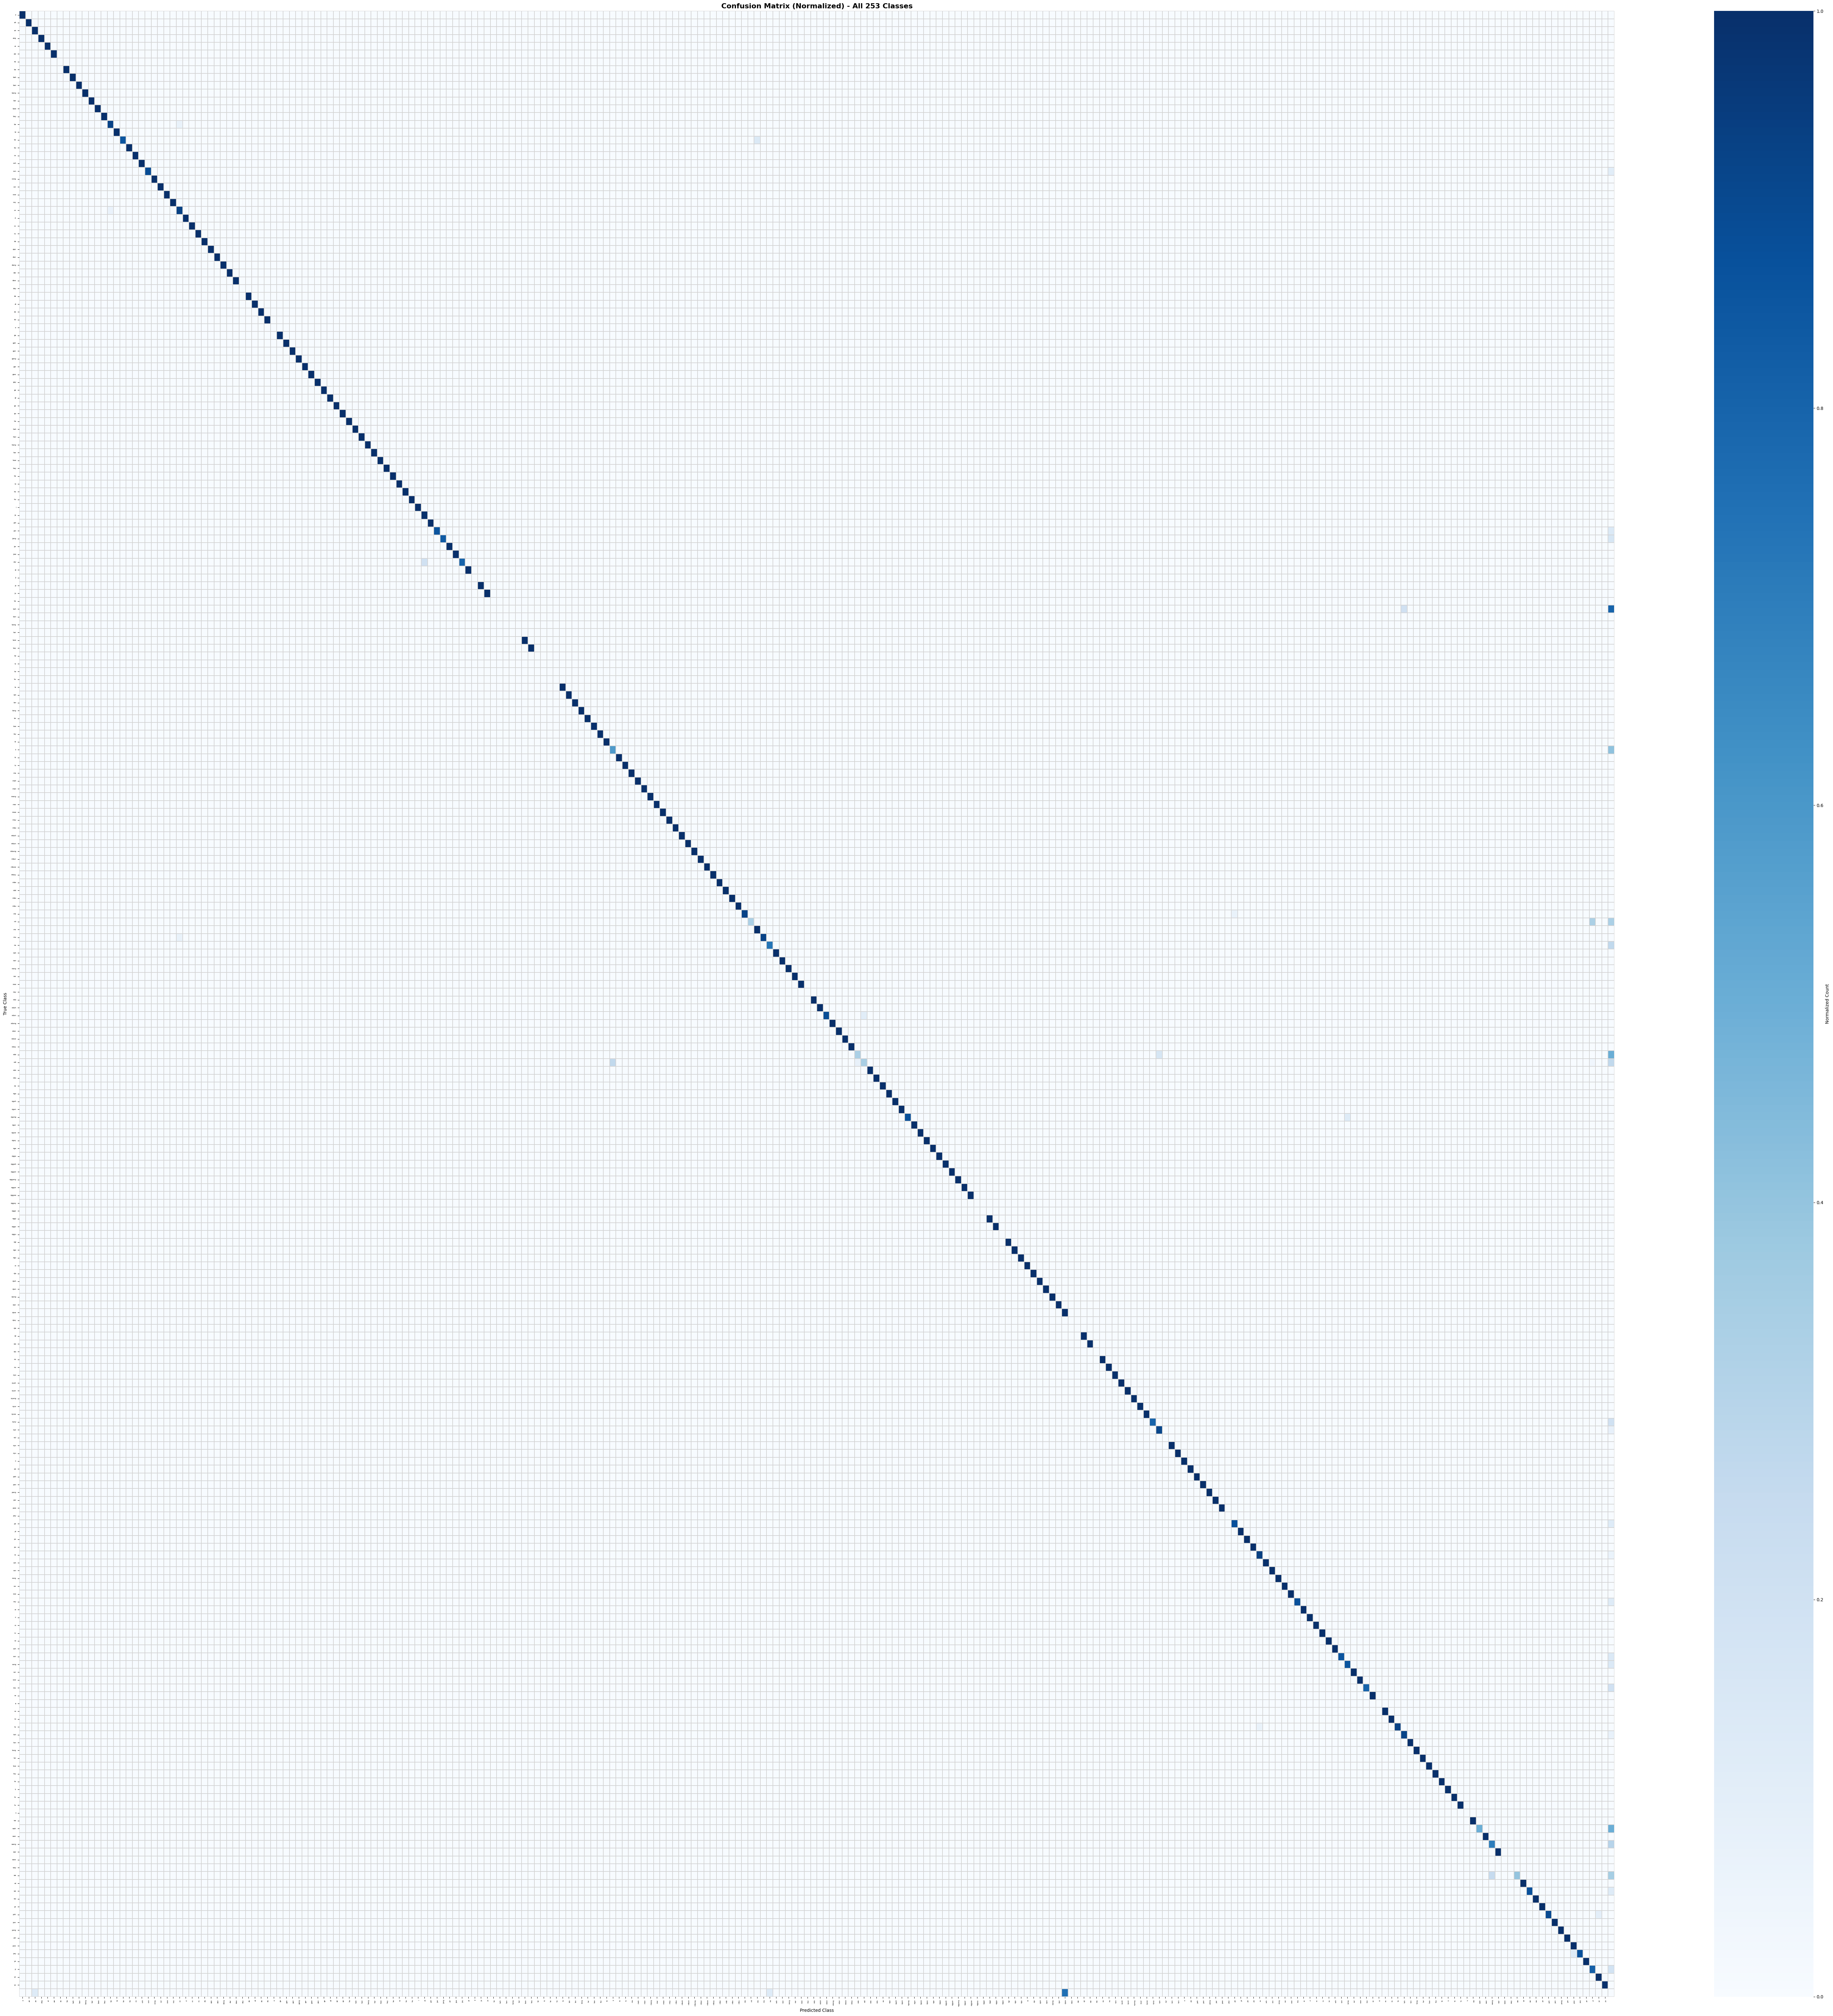

 Confusion matrix lengkap untuk 253 kelas disimpan ke /content/confusion_matrix_custom.png

 Ringkasan Confusion Matrix:
  Total prediksi   : 2003
  Jumlah kelas     : 254
  Jumlah prediksi benar (diagonal): 1903
  Akurasi kasar (total benar / total prediksi): 95.01%


In [ ]:
import glob, yaml
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

cm_object = val_metrics.confusion_matrix
cm_matrix = cm_object.matrix

# --- Plotting the Confusion Matrix ---
print("\n Membuat Confusion Matrix kustom (Full Matrix)...")

# Use all classes for the full confusion matrix
all_class_names = class_names

# If cm_matrix is empty or all zeros, it might indicate an issue with val_results.confusion_matrix.
# Let's add a check for that to provide feedback to the user.
if cm_matrix.sum() == 0 and len(all_class_names) > 0:
    print("Peringatan: Confusion matrix kosong (semua nol). Ini bisa disebabkan oleh masalah dalam deteksi atau konfigurasi evaluasi.")
    print("Tidak dapat membuat plot confusion matrix yang bermakna. Pastikan model melakukan deteksi.")
    # Skip plotting if matrix is empty
else:
    # Use the full confusion matrix
    full_cm = cm_matrix

    # Normalize for better visualization
    # Add a small epsilon to avoid division by zero for classes with no true instances
    row_sums = full_cm.sum(axis=1)
    full_cm_normalized = np.zeros_like(full_cm, dtype=float)
    for i in range(full_cm.shape[0]):
        if row_sums[i] > 0:
            full_cm_normalized[i, :] = full_cm[i, :] / row_sums[i]

    # Dynamically adjust figure size based on number of classes
    # For 253 classes, a figure width/height of ~60-70 will give decent resolution.
    fig_dim = max(15, int(len(all_class_names) * 0.25)) # Adjust multiplier as needed

    fig, ax = plt.subplots(figsize=(fig_dim, fig_dim)) # Increased figure size for better readability
    sns.heatmap(full_cm_normalized, annot=False, fmt=".2f", cmap="Blues", ax=ax,
                xticklabels=all_class_names, yticklabels=all_class_names,
                cbar_kws={'label': 'Normalized Count'}, linewidths=0.1, linecolor='lightgray') # Add lines for better separation

    # Adjust font sizes for labels if there are many classes
    if len(all_class_names) > 50:
        ax.tick_params(axis='x', labelsize=4) # Smaller font for many x-labels
        ax.tick_params(axis='y', labelsize=4) # Smaller font for many y-labels
        plt.setp(ax.get_xticklabels(), rotation=90, ha='right', rotation_mode="anchor")
        plt.setp(ax.get_yticklabels(), rotation=0, ha='right') # Fixed string literal
        ax.set_title(f'Confusion Matrix (Normalized) - All {len(all_class_names)} Classes', fontsize=16, fontweight='bold')
    else:
        plt.xticks(rotation=90) # Rotate x-axis labels
        plt.yticks(rotation=0)  # Ensure y-axis labels are horizontal
        ax.set_title(f'Confusion Matrix (Normalized) - All {len(all_class_names)} Classes', fontsize=14, fontweight='bold')

    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('True Class')
    plt.tight_layout()
    plt.savefig('/content/confusion_matrix_custom.png', dpi=300, bbox_inches='tight') # Higher DPI for better quality
    plt.show()
    print(f" Confusion matrix lengkap untuk {len(all_class_names)} kelas disimpan ke /content/confusion_matrix_custom.png")

# Ringkasan Confusion Matrix (this part can remain, but calculate based on full_cm if possible)
print("\n Ringkasan Confusion Matrix:")
if cm_matrix.sum() > 0:
    print(f"  Total prediksi   : {cm_matrix.sum():.0f}") # Convert to int
    print(f"  Jumlah kelas     : {cm_matrix.shape[0]}")
    print(f"  Jumlah prediksi benar (diagonal): {np.diag(cm_matrix).sum():.0f}") # Convert to int
    print(f"  Akurasi kasar (total benar / total prediksi): {(np.diag(cm_matrix).sum() / cm_matrix.sum()) * 100:.2f}%")
else:
    print(f"  Total prediksi   : 0")
    print(f"  Jumlah kelas     : {cm_matrix.shape[0]}")
    print(f"  Jumlah prediksi benar (diagonal): 0")
    print(f"  Akurasi kasar (total benar / total prediksi): Tidak dapat dihitung (total prediksi 0 atau matrix kosong).")

## CELL 10 — Bar Chart Precision, Recall, F1 per Kelas



 Bar chart per kelas berhasil dibuat!


In [ ]:
# ============================================================
# CELL 10: Bar chart Precision, Recall, F1 per kelas
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

csv_path = Path('/content/per_class_metrics.csv')
if not csv_path.exists():
    print(" per_class_metrics.csv tidak ditemukan. Jalankan Cell 7 terlebih dahulu.")
else:
    df = pd.read_csv(csv_path)
    # Hapus baris rata-rata untuk plot per kelas
    df_cls = df[df['Kelas'] != ' RATA-RATA'].copy()

    n_cls = len(df_cls)
    x = np.arange(n_cls)
    width = 0.25

    fig, axes = plt.subplots(2, 1, figsize=(max(14, n_cls * 0.8), 14))
    fig.suptitle('Metrik per Kelas — Aksara Ulu Rejang (YOLOv8s)',
                 fontsize=16, fontweight='bold')

    # ---- Plot 1: Grouped bar P/R/F1 ----
    ax = axes[0]
    bars_p  = ax.bar(x - width, df_cls['Precision'], width, label='Precision', color='#4472C4', alpha=0.85, edgecolor='black', lw=0.5)
    bars_r  = ax.bar(x,         df_cls['Recall'],    width, label='Recall',    color='#ED7D31', alpha=0.85, edgecolor='black', lw=0.5)
    bars_f1 = ax.bar(x + width, df_cls['F1-Score'],  width, label='F1-Score',  color='#70AD47', alpha=0.85, edgecolor='black', lw=0.5)

    # Tambah nilai di atas bar
    for bars in [bars_p, bars_r, bars_f1]:
        for bar in bars:
            h = bar.get_height()
            if h > 0.01:
                ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h:.2f}',
                        ha='center', va='bottom', fontsize=6.5, rotation=90)

    ax.axhline(df_cls['Precision'].mean(), color='#4472C4', linestyle='--', alpha=0.5, lw=1.5)
    ax.axhline(df_cls['Recall'].mean(),    color='#ED7D31', linestyle='--', alpha=0.5, lw=1.5)
    ax.axhline(df_cls['F1-Score'].mean(),  color='#70AD47', linestyle='--', alpha=0.5, lw=1.5)

    ax.set_title('Precision, Recall & F1-Score per Kelas', fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(df_cls['Kelas'].str[:12], rotation=45, ha='right', fontsize=9)
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1.15)
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)

    # ---- Plot 2: AP@50 per kelas ----
    ax2 = axes[1]
    colors_ap = ['#2ECC71' if v >= 0.7 else '#F39C12' if v >= 0.5 else '#E74C3C'
                 for v in df_cls['AP@50']]
    bars_ap = ax2.bar(x, df_cls['AP@50'], color=colors_ap, alpha=0.85, edgecolor='black', lw=0.5, width=0.6)

    for bar, val in zip(bars_ap, df_cls['AP@50']):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{val:.2f}',
                 ha='center', va='bottom', fontsize=8, fontweight='bold')

    ax2.axhline(df_cls['AP@50'].mean(), color='black', linestyle='--', lw=1.5,
                label=f"Rata-rata mAP@50: {df_cls['AP@50'].mean():.4f}")
    ax2.axhline(0.7, color='green', linestyle=':', lw=1, alpha=0.7, label='Target 70%')
    ax2.set_title('AP@50 per Kelas', fontweight='bold')
    ax2.set_xticks(x)
    ax2.set_xticklabels(df_cls['Kelas'].str[:12], rotation=45, ha='right', fontsize=9)
    ax2.set_ylabel('AP@50')
    ax2.set_ylim(0, 1.15)
    ax2.legend(fontsize=10)
    ax2.grid(axis='y', alpha=0.3)

    # Legend warna
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='#2ECC71', label='AP ≥ 0.70 (Baik)'),
        Patch(facecolor='#F39C12', label='AP 0.50-0.70 (Cukup)'),
        Patch(facecolor='#E74C3C', label='AP < 0.50 (Perlu Improve)'),
    ]
    ax2.legend(handles=legend_elements, loc='upper right', fontsize=9)

    plt.tight_layout()
    plt.savefig('/content/per_class_metrics_chart.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(" Bar chart per kelas berhasil dibuat!")

## CELL 11 — Inference & Visualisasi Prediksi

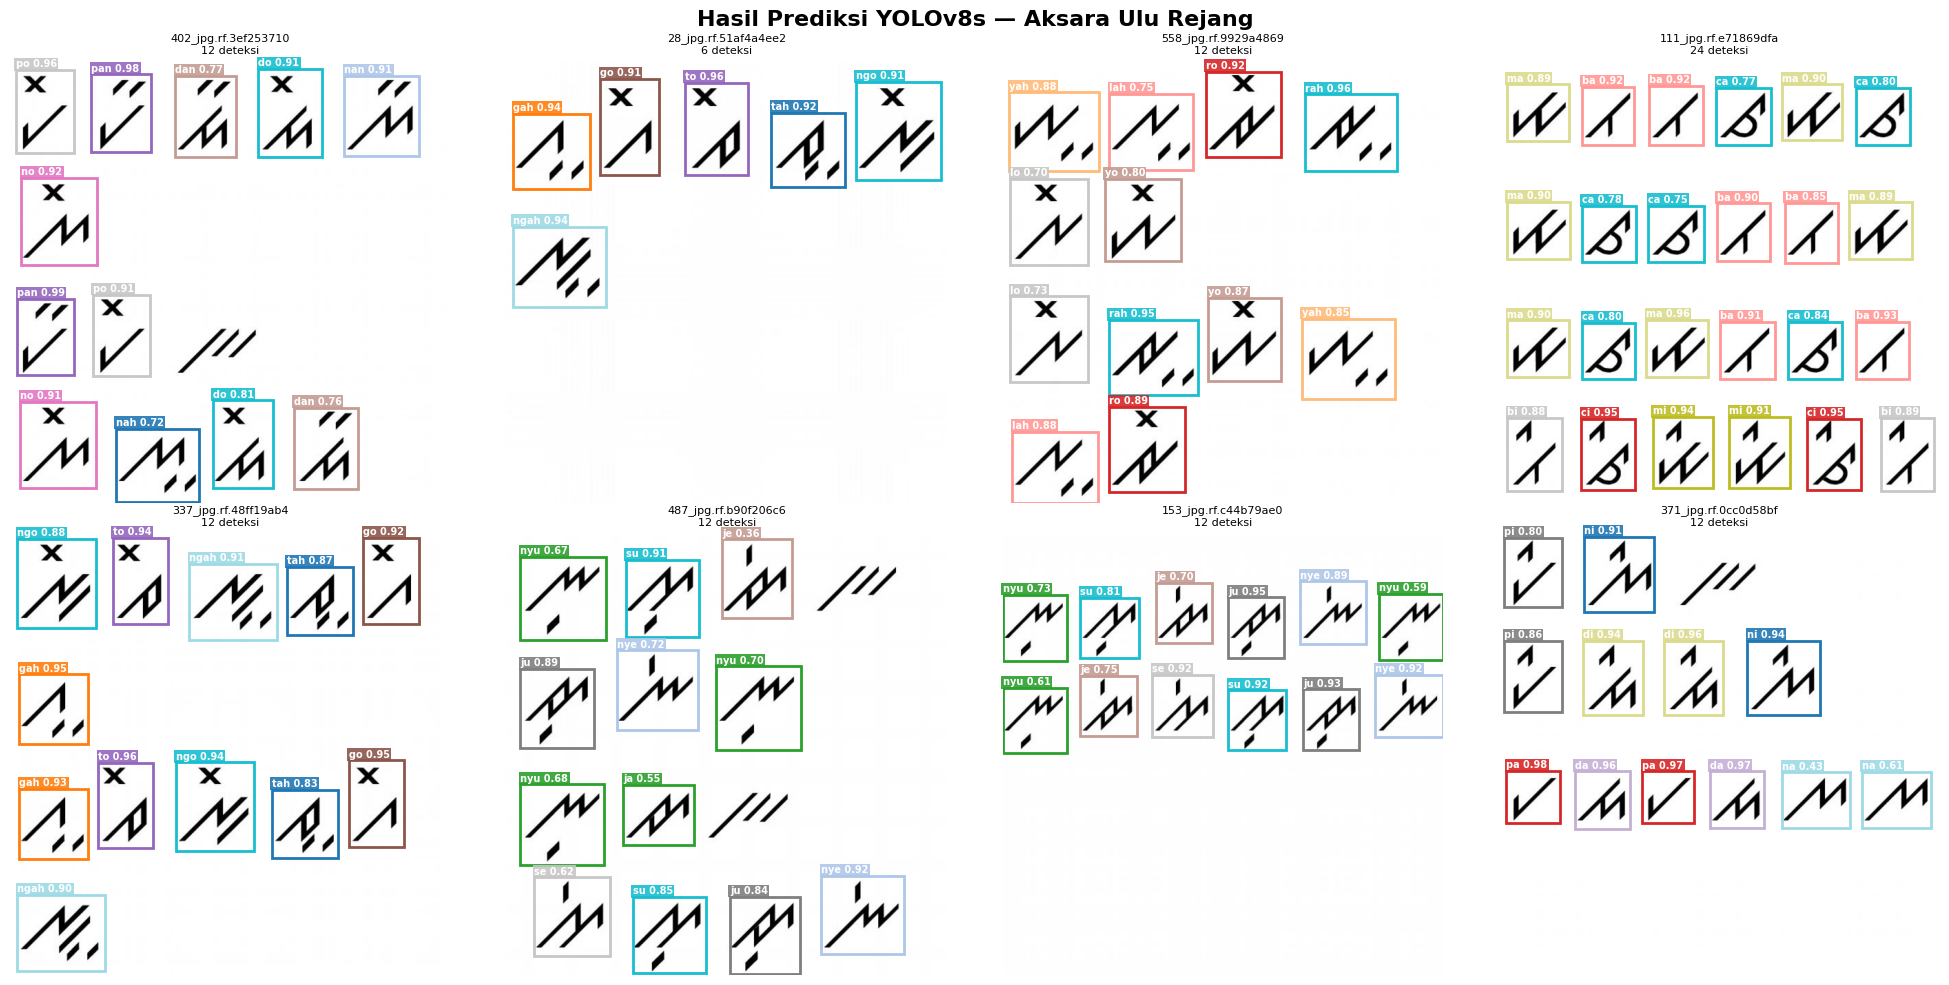

 Inference selesai!


In [ ]:
# ============================================================
# CELL 11: Inference pada gambar validation set
# ============================================================

import glob, yaml, random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
from ultralytics import YOLO

BEST_MODEL = glob.glob("/content/runs/kaganga_yolov8s/weights/best.pt")[0]
DATA_YAML  = str(list(Path("/content/dataset").rglob("data.yaml"))[0])

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
class_names = cfg.get('names', [])
val_dir = Path(cfg.get('val', ''))

model = YOLO(BEST_MODEL)

# Ambil sampel gambar dari val set
val_imgs = list(val_dir.glob("*.jpg")) + list(val_dir.glob("*.png"))
sample = random.sample(val_imgs, min(8, len(val_imgs)))

# Jalankan inference
results_infer = model.predict(
    source=[str(p) for p in sample],
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=0,
    verbose=False,
)

# Plot hasil inference
COLORS = plt.cm.tab20.colors
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Hasil Prediksi YOLOv8s — Aksara Ulu Rejang',
             fontsize=16, fontweight='bold')

for ax, (img_path, result) in zip(axes.flatten(), zip(sample, results_infer)):
    img = Image.open(img_path).convert('RGB')
    W, H = img.size

    fig2, ax2 = plt.subplots(1, 1)
    ax.imshow(img)
    ax.axis('off')

    boxes = result.boxes
    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            cls_id = int(box.cls[0])
            conf   = float(box.conf[0])
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            color = COLORS[cls_id % len(COLORS)][:3]
            rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                      linewidth=2, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            label = f"{class_names[cls_id] if cls_id < len(class_names) else cls_id} {conf:.2f}"
            ax.text(x1, y1-4, label, color='white', fontsize=7, fontweight='bold',
                    bbox=dict(facecolor=color, alpha=0.9, pad=1, edgecolor='none'))

    n_det = len(boxes) if boxes is not None else 0
    ax.set_title(f"{img_path.name[:20]}\n{n_det} deteksi", fontsize=8)
    plt.close(fig2)

for ax in axes.flatten()[len(sample):]:
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/inference_results.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Inference selesai!")

In [ ]:
# =======================================================
# Menampilkan data mentah prediksi
# =======================================================

import glob, yaml, random
from PIL import Image
from pathlib import Path
from ultralytics import YOLO

BEST_MODEL = glob.glob("/content/runs/kaganga_yolov8s/weights/best.pt")[0]
DATA_YAML  = str(list(Path("/content/dataset").rglob("data.yaml"))[0])

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
class_names = cfg.get('names', [])
val_dir = Path(cfg.get('val', ''))

model = YOLO(BEST_MODEL)

# Ambil satu sampel gambar acak dari validation set
val_imgs = list(val_dir.glob("*.jpg")) + list(val_dir.glob("*.png"))
if val_imgs:
    sample_img_path = random.choice(val_imgs)
    print(f"Melakukan inferensi pada gambar: {sample_img_path.name}\n")

    # Jalankan inference pada satu gambar
    # conf=0.25 (confidence threshold) dan iou=0.45 (NMS IOU threshold)
    results_single_img = model.predict(
        source=str(sample_img_path),
        conf=0.25,
        iou=0.45,
        imgsz=640,
        device=0,
        verbose=False,
        save=False, # Jangan simpan gambar ke disk
        show=False  # Jangan tampilkan secara otomatis
    )

    # Ambil hasil untuk gambar pertama (dan satu-satunya)
    result = results_single_img[0]

    print("--- Data Prediksi Mentah ---")
    if result.boxes is not None and len(result.boxes) > 0:
        for i, box in enumerate(result.boxes):
            cls_id = int(box.cls[0])
            conf   = float(box.conf[0])
            # Bounding box dalam format xyxy (top-left x, top-left y, bottom-right x, bottom-right y)
            x1, y1, x2, y2 = [round(coord, 2) for coord in box.xyxy[0].tolist()]

            label = class_names[cls_id] if cls_id < len(class_names) else f"Unknown_{cls_id}"
            print(f"Deteksi {i+1}:")
            print(f"  Class   : {label} (ID: {cls_id})")
            print(f"  Conf.   : {conf:.4f}")
            print(f"  BBox    : [x1={x1}, y1={y1}, x2={x2}, y2={y2}]")
    else:
        print("Tidak ada objek yang terdeteksi pada gambar ini dengan ambang batas yang diberikan.")
    print("----------------------------")
else:
    print("Tidak ada gambar di direktori validasi untuk diuji.")


Melakukan inferensi pada gambar: 72_jpg.rf.76f7d3b3e63c4261c4c933640ee14829.jpg

--- Data Prediksi Mentah ---
Deteksi 1:
  Class   : pe (ID: 193)
  Conf.   : 0.9782
  BBox    : [x1=521.05, y1=338.37, x2=602.91, y2=437.93]
Deteksi 2:
  Class   : de (ID: 36)
  Conf.   : 0.9568
  BBox    : [x1=32.99, y1=25.05, x2=115.82, y2=131.81]
Deteksi 3:
  Class   : de (ID: 36)
  Conf.   : 0.9546
  BBox    : [x1=33.72, y1=489.6, x2=117.33, y2=595.8]
Deteksi 4:
  Class   : pe (ID: 193)
  Conf.   : 0.9539
  BBox    : [x1=254.15, y1=26.48, x2=333.86, y2=123.9]
Deteksi 5:
  Class   : ne (ID: 137)
  Conf.   : 0.9474
  BBox    : [x1=151.64, y1=337.2, x2=256.84, y2=443.86]
Deteksi 6:
  Class   : nu (ID: 173)
  Conf.   : 0.9389
  BBox    : [x1=500.71, y1=48.43, x2=608.78, y2=160.97]
Deteksi 7:
  Class   : du (ID: 39)
  Conf.   : 0.9362
  BBox    : [x1=31.38, y1=364.01, x2=116.49, y2=471.59]
Deteksi 8:
  Class   : nu (ID: 173)
  Conf.   : 0.9355
  BBox    : [x1=286.09, y1=362.03, x2=391.54, y2=473.83]
Deteksi

GIF demo deteksi disimpan ke: /content/detection_process_demo.gif


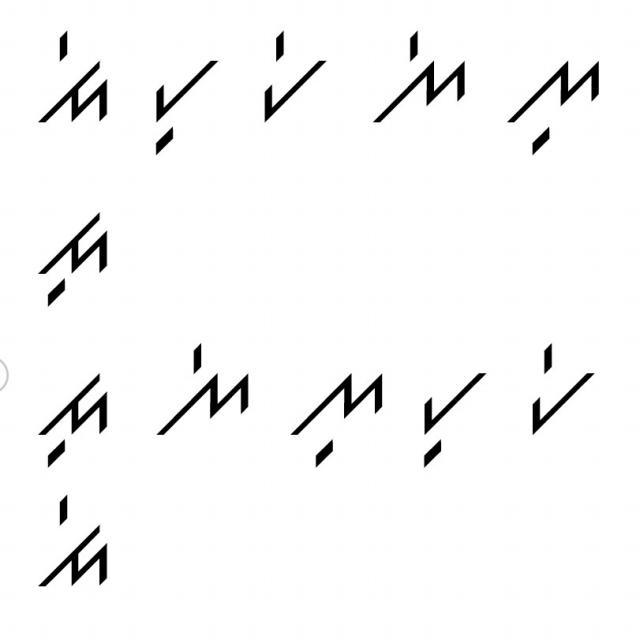

GIF demo proses deteksi berhasil dibuat!


In [ ]:
# ============================================================
# Buat GIF yang menunjukkan proses deteksi
# ============================================================

import imageio.v2 as imageio
from PIL import ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import os

# Memastikan 'result' dan 'sample_img_path' tersedia dari cell sebelumnya
if 'result' in locals() and 'sample_img_path' in locals():
    raw_img_pil = Image.open(sample_img_path).convert('RGB')
    W, H = raw_img_pil.size

    # --- Frame 1: Gambar Asli (Tanpa Label) ---
    # Kita bisa langsung menggunakan objek raw_img_pil

    # --- Frame 2: Gambar dengan Prediksi (Dengan Label) ---
    predicted_img_pil = raw_img_pil.copy()
    draw = ImageDraw.Draw(predicted_img_pil)

    # Load a default font
    try:
        font = ImageFont.truetype("arial.ttf", 12)
    except IOError:
        font = ImageFont.load_default()

    COLORS = plt.cm.tab20.colors # Reuse COLORS from previous cells

    boxes = result.boxes
    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            cls_id = int(box.cls[0])
            conf   = float(box.conf[0])
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            color = tuple(int(c*255) for c in COLORS[cls_id % len(COLORS)][:3])

            # Draw rectangle
            draw.rectangle([x1, y1, x2, y2], outline=color, width=2)

            # Draw label background and text
            label = f"{class_names[cls_id] if cls_id < len(class_names) else cls_id} {conf:.2f}"
            bbox_text = draw.textbbox((0, 0), label, font=font)
            text_w, text_h = bbox_text[2] - bbox_text[0], bbox_text[3] - bbox_text[1]

            text_y1 = max(0, y1 - text_h - 2)
            draw.rectangle([x1, text_y1, x1 + text_w + 4, y1], fill=color)
            draw.text((x1 + 2, text_y1), label, fill='white', font=font)

    # --- Buat GIF ---
    gif_filename = '/content/detection_process_demo.gif'
    imageio.mimsave(gif_filename, [raw_img_pil, predicted_img_pil], fps=1, loop=0)

    print(f"GIF demo deteksi disimpan ke: {gif_filename}")

    # Tampilkan GIF di Colab
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=gif_filename))

    print("GIF demo proses deteksi berhasil dibuat!")
else:
    print("Tidak dapat membuat GIF karena hasil inferensi dari cell sebelumnya tidak ditemukan.")


## CELL 12 — Export & Download Semua Hasil

In [ ]:
# ============================================================
# CELL 12: Export hasil ke ZIP & download ke lokal
# ============================================================

import shutil, glob, os
from pathlib import Path
from google.colab import files

EXPORT_DIR = Path("/content/kaganga_results")
EXPORT_DIR.mkdir(exist_ok=True)

# File yang perlu di-export
files_to_copy = {
    # Model weights
    "/content/runs/kaganga_yolov8s/weights/best.pt"  : "model/best.pt",
    "/content/runs/kaganga_yolov8s/weights/last.pt"  : "model/last.pt",

    # Training configuration (very important for reproducibility)
    "/content/runs/kaganga_yolov8s/args.yaml"        : "training/args.yaml",
    "/content/dataset/data.yaml"                     : "dataset/data.yaml", # The dataset configuration

    # Training results
    "/content/runs/kaganga_yolov8s/results.csv"      : "training/results.csv",
    "/content/loss_curves.png"                       : "plots/loss_curves.png",
    "/content/metrics_curves.png"                    : "plots/metrics_curves.png",

    # Evaluasi
    "/content/per_class_metrics.csv"                 : "evaluation/per_class_metrics.csv",
    "/content/per_class_metrics_chart.png"           : "evaluation/per_class_metrics_chart.png",
    "/content/confusion_matrix_custom.png"           : "evaluation/confusion_matrix_custom.png",

    # Dataset exploration
    "/content/dataset_exploration.png"               : "dataset/dataset_exploration.png",
    "/content/dataset_samples.png"                   : "dataset/dataset_samples.png",

    # Inference & Demo
    "/content/inference_results.png"                 : "inference/inference_results.png",
    "/content/detection_process_demo.gif"            : "inference/detection_process_demo.gif",
}

# Tambahkan YOLOv8 built-in plots
for png in glob.glob("/content/runs/kaganga_yolov8s/*.png"):
    files_to_copy[png] = f"training/{Path(png).name}"
for png in glob.glob("/content/runs/kaganga_eval/*.png"):
    files_to_copy[png] = f"evaluation/{Path(png).name}"

# Salin semua
print(" Mengemas hasil...")
copied, skipped = 0, 0
for src, dst in files_to_copy.items():
    src_path = Path(src)
    dst_path = EXPORT_DIR / dst
    dst_path.parent.mkdir(parents=True, exist_ok=True)
    if src_path.exists():
        shutil.copy2(src_path, dst_path)
        print(f" {dst}")
        copied += 1
    else:
        print(f"  Tidak ada: {src}")
        skipped += 1

# ZIP
zip_path = "/content/kaganga_yolov8s_results"
shutil.make_archive(zip_path, 'zip', str(EXPORT_DIR))

print(f"\n Export selesai! ({copied} file disalin, {skipped} dilewati)")
print(f" ZIP: {zip_path}.zip")

# Download otomatis
files.download(f"{zip_path}.zip")
print("\n Download dimulai!")

 Mengemas hasil...
 model/best.pt
 model/last.pt
 training/args.yaml
 dataset/data.yaml
 training/results.csv
 plots/loss_curves.png
 plots/metrics_curves.png
 evaluation/per_class_metrics.csv
 evaluation/per_class_metrics_chart.png
 evaluation/confusion_matrix_custom.png
 dataset/dataset_exploration.png
 dataset/dataset_samples.png
 inference/inference_results.png
 inference/detection_process_demo.gif
 training/confusion_matrix_normalized.png
 training/BoxP_curve.png
 training/results.png
 training/BoxR_curve.png
 training/confusion_matrix.png
 training/BoxF1_curve.png
 training/BoxPR_curve.png
 evaluation/confusion_matrix_normalized.png
 evaluation/BoxP_curve.png
 evaluation/BoxR_curve.png
 evaluation/confusion_matrix.png
 evaluation/BoxF1_curve.png
 evaluation/BoxPR_curve.png

 Export selesai! (27 file disalin, 0 dilewati)
 ZIP: /content/kaganga_yolov8s_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


 Download dimulai!


## CELL 13 — Ringkasan Laporan Akurasi Final

In [ ]:
# ============================================================
# CELL 13: Cetak laporan akurasi final yang rapi
# ============================================================

import glob, yaml, pandas as pd
from pathlib import Path
from ultralytics import YOLO

BEST_MODEL = glob.glob("/content/runs/kaganga_yolov8s/weights/best.pt")[0]
DATA_YAML  = str(list(Path("/content/dataset").rglob("data.yaml"))[0])

with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
class_names = cfg.get('names', [])

model = YOLO(BEST_MODEL)
info = model.info(verbose=False)

val_m = model.val(data=DATA_YAML, split='val', imgsz=640, batch=16,
                  conf=0.25, iou=0.5, device=0, verbose=False, plots=False)

P  = val_m.box.mp
R  = val_m.box.mr
F1 = 2 * P * R / (P + R + 1e-10)
mAP50    = val_m.box.map50
mAP5095  = val_m.box.map

print()
print("=" * 65)
print("    LAPORAN AKURASI FINAL — DETEKSI AKSARA ULU REJANG")
print("    Model: YOLOv8s | Dataset: Roboflow Aksara Ulu Rejang")
print("=" * 65)
print(f"  Jumlah kelas   : {len(class_names)}")
print(f"  Nama kelas     : {', '.join(class_names[:5])}{'...' if len(class_names)>5 else ''}")
print("-" * 65)
print(f"  mAP@50         : {mAP50:.4f}   ({mAP50*100:.2f}%)")
print(f"  mAP@50-95      : {mAP5095:.4f}   ({mAP5095*100:.2f}%)")
print(f"  Precision      : {P:.4f}   ({P*100:.2f}%)")
print(f"  Recall         : {R:.4f}   ({R*100:.2f}%)")
print(f"  F1 Score       : {F1:.4f}   ({F1*100:.2f}%)")
print("=" * 65)
print()

# Per-class table
csv_path = Path('/content/per_class_metrics.csv')
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("METRIK PER KELAS:")
    print(f"{'Kelas':<18} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AP@50':>8}")
    print(" " + "-"*55)
    for _, row in df.iterrows():
        marker = "→" if row['Kelas'] == ' RATA-RATA' else " "
        print(f"  {marker} {str(row['Kelas'])[:17]:<17} {row['Precision']:>10.4f} {row['Recall']:>8.4f} {row['F1-Score']:>8.4f} {row['AP@50']:>8.4f}")

print()
print("File Tersedia:")
print("/content/loss_curves.png")
print("/content/metrics_curves.png")
print("/content/confusion_matrix_custom.png")
print("/content/per_class_metrics.csv")
print("/content/runs/kaganga_yolov8s/weights/best.pt")
print("=" * 65)
print("Semua evaluasi selesai! Gunakan Cell 12 untuk download.")
print("=" * 65)

Ultralytics 8.4.46 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,223,495 parameters, 0 gradients, 29.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 725.1±201.5 MB/s, size: 22.7 KB)
val: Scanning /content/dataset/valid/labels.cache... 135 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 135/135 51.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.3it/s 2.1s
                   all        135       1941      0.978      0.993      0.987      0.787
Speed: 1.1ms preprocess, 9.4ms inference, 0.0ms loss, 0.9ms postprocess per image

    LAPORAN AKURASI FINAL — DETEKSI AKSARA ULU REJANG
    Model: YOLOv8s | Dataset: Roboflow Aksara Ulu Rejang
  Jumlah kelas   : 253
  Nama kelas     : a, ah, an, ang, ar...
-----------------------------------------------------------------
  mAP@50         : 0.9869   (98.69%)
  mAP@50-95      : 0.7870   (78.70%)
  Precis